# Fig. 3 — surface vs. behavioural similarity (scatter, statistics and Mantel test)

Rebuilds the Section 5.1 scatter as a vector PDF from `data/surface_vs_behaviour/recursion_real_outputs.csv` (the 16 prompts and the Qwen2.5-7B-Instruct outputs produced by `experiments/surface_vs_behaviour/`). Prompts and outputs are re-embedded with `all-MiniLM-L6-v2` at full precision — the same embedder and inputs as the GPU run.

**Why re-embed instead of loading the saved matrices.** The saved `prompt_similarities.txt` / `output_similarities.txt` are rounded to 2 decimals and give Pearson r = 0.4875; full-precision embeddings give r = 0.4837, the value reported in the paper. Cell 5 checks this.

**Input:** `recursion_real_outputs.csv` (columns `prompt_id`, `category`, `prompt_text`, `output_text`; 16 rows).

**Outputs:** `fig_similarity_scatter.pdf` (vector), `fig_similarity_scatter.png` (600 dpi preview), `fig3_manifest.json` (input hash, computed values, software versions).

## 1. Environment

`sentence-transformers` pulls in torch. On a fresh Colab runtime this takes 1–2 minutes. No GPU is needed — 16 short texts embed fine on CPU.

In [1]:
!pip install -q sentence-transformers

import json, hashlib, platform, sys
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

print("numpy      ", np.__version__)
print("pandas     ", pd.__version__)
print("scipy      ", scipy.__version__)
print("matplotlib ", matplotlib.__version__)

numpy       2.1.3
pandas      2.2.3
scipy       1.16.3
matplotlib  3.10.0


## 2. Upload the source CSV

Run this cell and pick `recursion_real_outputs.csv` from your machine. If you are running locally instead of Colab, skip this cell and set `CSV_PATH` in cell 3 to your own path.

In [2]:
try:
    from google.colab import files
    uploaded = files.upload()
    CSV_PATH = list(uploaded.keys())[0]
except ImportError:
    CSV_PATH = "recursion_real_outputs.csv"   # local fallback — edit if needed

print("Using:", CSV_PATH)

Saving recursion_real_outputs.csv to recursion_real_outputs.csv
Using: recursion_real_outputs.csv


## 3. Load and hash the input

The SHA-256 of the input file is written to the manifest, so the figure can be tied to this exact file.

In [3]:
with open(CSV_PATH, "rb") as f:
    INPUT_SHA256 = hashlib.sha256(f.read()).hexdigest()

df = pd.read_csv(CSV_PATH)
df = df.sort_values("prompt_id").reset_index(drop=True)

N_PROMPTS = len(df)
assert N_PROMPTS == 16, f"Expected 16 prompts, found {N_PROMPTS}"

print(f"SHA-256: {INPUT_SHA256}")
print(f"Rows:    {N_PROMPTS}")
print(f"Columns: {list(df.columns)}")
df[["prompt_id", "category"]]

SHA-256: cf995bf987d86dc77a86bfb67edba974fc5e39377e5cca1c76aba431ea47106d
Rows:    16
Columns: ['prompt_id', 'category', 'prompt_text', 'output_text']


,prompt_id,category
0,P1,instruction
1,P10,reasoning
2,P11,reasoning
3,P12,reasoning
4,P13,format
5,P14,format
6,P15,format
7,P16,format
8,P2,instruction
9,P3,instruction


## 4. Embed and build the two 16×16 cosine matrices

`all-MiniLM-L6-v2` with `normalize_embeddings=True`, so the cosine similarity is just the dot product. This reproduces the original run's embedder exactly.

In [4]:
from sentence_transformers import SentenceTransformer
import sentence_transformers, torch

EMBEDDER = "all-MiniLM-L6-v2"
model = SentenceTransformer(EMBEDDER)

prompt_emb = model.encode(df["prompt_text"].tolist(),
                          normalize_embeddings=True,
                          convert_to_numpy=True).astype(np.float64)
output_emb = model.encode(df["output_text"].tolist(),
                          normalize_embeddings=True,
                          convert_to_numpy=True).astype(np.float64)

P = prompt_emb @ prompt_emb.T      # 16 x 16 prompt-pair cosine
O = output_emb @ output_emb.T      # 16 x 16 output-pair cosine

iu = np.triu_indices(N_PROMPTS, k=1)   # strict upper triangle -> 120 unique pairs
x = P[iu]
y = O[iu]

assert len(x) == 120, f"Expected 120 pairs, got {len(x)}"
print(f"n_pairs = {len(x)}")
print(f"prompt-pair mean = {x.mean():.12f}")
print(f"output-pair mean = {y.mean():.12f}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

n_pairs = 120
prompt-pair mean = 0.694413434887
output-pair mean = 0.671195370550


## 5. Verification checkpoint

Reference values from the original GPU run at full precision. If an assert fires, something differs from that run (embedder version, input file or prompt list).

Tolerance is `1e-6`: loose enough to absorb library-version float noise, tight enough to catch a genuinely different computation.

In [5]:
TOL = 1e-6

REFERENCE = {
    "prompt_sim_mean": 0.694413423538,
    "output_sim_mean": 0.671195328236,
    "pearson_r":       0.483736395836,
    "spearman_rho":    0.144065560108,
    "spearman_p":      0.116451950500,
}

pearson_r, pearson_p = pearsonr(x, y)
spearman_rho, spearman_p = spearmanr(x, y)

computed = {
    "prompt_sim_mean": float(x.mean()),
    "output_sim_mean": float(y.mean()),
    "pearson_r":       float(pearson_r),
    "spearman_rho":    float(spearman_rho),
    "spearman_p":      float(spearman_p),
}

print(f"{'value':<18} {'computed':>16} {'reference':>16} {'diff':>12}   ok")
print("-" * 70)
all_ok = True
for k, ref in REFERENCE.items():
    got = computed[k]
    d = abs(got - ref)
    ok = d < TOL
    all_ok &= ok
    print(f"{k:<18} {got:>16.12f} {ref:>16.12f} {d:>12.2e}   {'PASS' if ok else 'FAIL'}")

print()
print(f"Pearson p = {pearson_p:.3e}  (paper: p < 0.001)")
print(f"R^2       = {pearson_r**2:.4f}  (paper: 0.23)")
assert all_ok, "Reference mismatch — do not use this figure. Investigate before proceeding."
print("\nAll reference values reproduce. Safe to plot.")

value                      computed        reference         diff   ok
----------------------------------------------------------------------
prompt_sim_mean      0.694413434887   0.694413423538     1.13e-08   PASS
output_sim_mean      0.671195370550   0.671195328236     4.23e-08   PASS
pearson_r            0.483736631920   0.483736395836     2.36e-07   PASS
spearman_rho         0.144065560108   0.144065560108     3.41e-13   PASS
spearman_p           0.116451950500   0.116451950500     3.69e-13   PASS

Pearson p = 2.182e-08  (paper: p < 0.001)
R^2       = 0.2340  (paper: 0.23)

All reference values reproduce. Safe to plot.


## 6. Mantel test

The GPU notebook reports Pearson and Spearman correlations; the Mantel test reported in the paper is computed here.

1. Exhaustive enumeration is impossible (16! ≈ 2.09 × 10¹³), so the test is Monte Carlo: 999,999 row-and-column permutations, seed 42.
2. The third decimal depends on the seed (a sweep at 199,999 permutations gives 0.060 / 0.060 / 0.059 for seeds 42 / 1 / 2026), so the permutation count and seed are stated with the result.

Runtime is roughly 1–3 minutes. Set `N_PERM = 9_999` for a quick check.

In [6]:
N_PERM = 999_999
SEED   = 42

rng = np.random.default_rng(SEED)
obs_r = float(np.corrcoef(x, y)[0, 1])

count = 0
for _ in range(N_PERM):
    perm = rng.permutation(N_PROMPTS)
    y_perm = O[np.ix_(perm, perm)][iu]
    if abs(np.corrcoef(x, y_perm)[0, 1]) >= abs(obs_r) - 1e-12:
        count += 1

mantel_p = (count + 1) / (N_PERM + 1)
mc_se = np.sqrt(mantel_p * (1 - mantel_p) / N_PERM)

print(f"Mantel r = {obs_r:.6f}   (equals the Pearson r over the upper triangles)")
print(f"two-sided p = {mantel_p:.6f}  (MC SE {mc_se:.6f}) -> {mantel_p:.3f}")
print(f"{N_PERM:,} permutations, seed {SEED}")

Mantel r = 0.483737   (equals the Pearson r over the upper triangles)
two-sided p = 0.060232  (MC SE 0.000238) -> 0.060
999,999 permutations, seed 42


## 7. Draw the figure

Style: purple markers with darker edges, a dashed black least-squares trend line spanning only the observed x-range, generous type sizes.

**Vector-quality settings :**
- `pdf.fonttype = 42` embeds TrueType outlines rather than Type 3, which some production systems reject.
- No `dpi` on the PDF save — it is vector, so it stays crisp at any zoom.
- `bbox_inches='tight'` trims whitespace without clipping the axis labels.

Adjust `FIGSIZE`, `MARKER_SIZE` or the two colours if you want a tighter visual match; everything else should stay as-is.

slope = 0.778315, intercept = 0.130723
Saved fig_similarity_scatter.pdf and .png


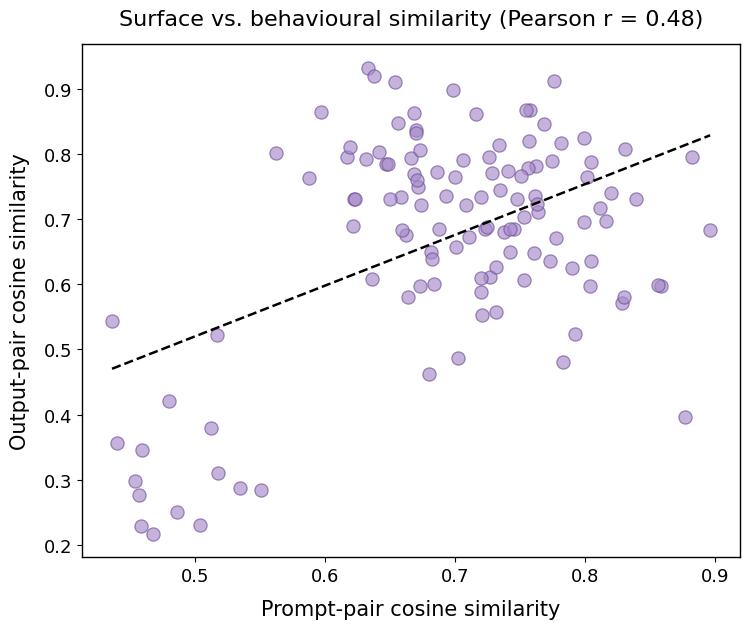

In [7]:
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"]  = 42
matplotlib.rcParams["font.family"]  = "DejaVu Sans"

FIGSIZE      = (7.6, 6.4)
MARKER_SIZE  = 90
FACE_COLOUR  = "#A78BC8"
EDGE_COLOUR  = "#6B4C9A"

fig, ax = plt.subplots(figsize=FIGSIZE)

ax.scatter(x, y,
           s=MARKER_SIZE,
           facecolor=FACE_COLOUR,
           edgecolor=EDGE_COLOUR,
           linewidth=0.9,
           alpha=0.65,
           zorder=3)

# Least-squares trend line, drawn only across the observed x-range
slope, intercept = np.polyfit(x, y, 1)
xs = np.array([x.min(), x.max()])
ax.plot(xs, slope * xs + intercept,
        color="black", linestyle="--", linewidth=1.8, zorder=4)

ax.set_xlabel("Prompt-pair cosine similarity", fontsize=15, labelpad=10)
ax.set_ylabel("Output-pair cosine similarity", fontsize=15, labelpad=10)
ax.set_title(f"Surface vs. behavioural similarity (Pearson r = {pearson_r:.2f})",
             fontsize=16, pad=14)
ax.tick_params(axis="both", labelsize=13)

for spine in ax.spines.values():
    spine.set_linewidth(1.0)

fig.tight_layout()

fig.savefig("fig_similarity_scatter.pdf", bbox_inches="tight")          # vector, for LaTeX
fig.savefig("fig_similarity_scatter.png", dpi=600, bbox_inches="tight") # raster preview

print(f"slope = {slope:.6f}, intercept = {intercept:.6f}")
print("Saved fig_similarity_scatter.pdf and .png")
plt.show()

## 8. Provenance manifest

Writes the input hash, every computed value and the software versions to JSON.

In [8]:
manifest = {
    "figure": "fig_similarity_scatter.pdf",
    "paper_section": "5.1",
    "description": "Prompt-pair vs output-pair cosine similarity, 120 unique pairs",
    "source_model": "Qwen2.5-7B-Instruct",
    "embedder": EMBEDDER,
    "input_file": CSV_PATH,
    "input_sha256": INPUT_SHA256,
    "n_prompts": int(N_PROMPTS),
    "n_pairs": int(len(x)),
    "values": {
        **{k: float(v) for k, v in computed.items()},
        "pearson_p": float(pearson_p),
        "r_squared": float(pearson_r ** 2),
        "trend_slope": float(slope),
        "trend_intercept": float(intercept),
        "mantel_r": float(obs_r),
        "mantel_p": float(mantel_p),
        "mantel_mc_se": float(mc_se),
    },
    "mantel_permutations": int(N_PERM),
    "mantel_seed": int(SEED),
    "mantel_note": "Monte Carlo; exhaustive enumeration infeasible (16! = 2.09e13). Third decimal is seed-dependent — always report count and seed.",
    "software": {
        "python": sys.version.split()[0],
        "platform": platform.platform(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
        "matplotlib": matplotlib.__version__,
        "torch": torch.__version__,
        "sentence_transformers": sentence_transformers.__version__,
    },
}

with open("fig3_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print(json.dumps(manifest, indent=2))

{
  "figure": "fig_similarity_scatter.pdf",
  "paper_section": "5.1",
  "description": "Prompt-pair vs output-pair cosine similarity, 120 unique pairs",
  "source_model": "Qwen2.5-7B-Instruct",
  "embedder": "all-MiniLM-L6-v2",
  "input_file": "recursion_real_outputs.csv",
  "input_sha256": "cf995bf987d86dc77a86bfb67edba974fc5e39377e5cca1c76aba431ea47106d",
  "n_prompts": 16,
  "n_pairs": 120,
  "values": {
    "prompt_sim_mean": 0.694413434886788,
    "output_sim_mean": 0.6711953705504257,
    "pearson_r": 0.48373663191999083,
    "spearman_rho": 0.14406556010834085,
    "spearman_p": 0.11645195049963132,
    "pearson_p": 2.1816609791841773e-08,
    "r_squared": 0.2340011290612967,
    "trend_slope": 0.7783146936841112,
    "trend_intercept": 0.13072319068638358,
    "mantel_r": 0.4837366319199909,
    "mantel_p": 0.060232,
    "mantel_mc_se": 0.00023791629364161416
  },
  "mantel_permutations": 999999,
  "mantel_seed": 42,
  "mantel_note": "Monte Carlo; exhaustive enumeration infeasi

## 9. Download

In LaTeX, reference the PDF without an extension so the engine picks it up cleanly:

```latex
\includegraphics[width=\linewidth]{fig_similarity_scatter}
```

In [9]:
try:
    from google.colab import files
    files.download("fig_similarity_scatter.pdf")
    files.download("fig_similarity_scatter.png")
    files.download("fig3_manifest.json")
except ImportError:
    print("Not in Colab — files are in the working directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>